# Lab 3: The Document Agent

We now put the pieces together. Everything you build here lives in `doc_agent.py`, `doc_tools.py` and `api.py` at the end, in the same way the Sidekick lives in `sidekick.py`.

```
User request
   -> FastAPI (validates the input)
   -> LangGraph:  PLAN (LLM writes its own TODO list)
                  EXECUTE (LLM writes one section per visit, loops until the list is done)
                  BUILD (a tool creates the Word document)
   -> every LLM call goes through ask(): Pydantic structured output + retry + fallback
   -> response: task list + assumptions + download link
```

**Before you run this**

You need an `OPENAI_API_KEY` in a `.env` file next to this notebook:

```
OPENAI_API_KEY=sk-...
```
The model name lives in one constant near the top so you can change it in one place.

In [1]:
import os
import time
import json
import operator
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

load_dotenv(override=True)

PRIMARY_MODEL = "gpt-6-luna"
FALLBACK_MODEL = "gpt-5.4-mini"   # put a different or cheaper model here if you have one
RETRY_DELAY = 1
MAX_TASKS = 7


def show(graph):
    """Draw the graph. The PNG render needs internet, so fall back to Mermaid text."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

## Part 1: schemas and the safe LLM call

These are exactly the pieces from Lab 1, repeated so this notebook runs on its own.

In [2]:
class Task(BaseModel):
    """One item in the agent's TODO list."""
    id: int
    section: str = Field(description="Section name, for example 'Risks'")
    goal: str = Field(description="What this section must achieve")


class Plan(BaseModel):
    """What the planner returns."""
    doc_type: str = Field(description="proposal, project plan, SOP, business report, etc.")
    title: str
    assumptions: list[str] = Field(description="Assumptions for missing information and resolved conflicts")
    tasks: list[Task] = Field(description="4 to 7 tasks, one per document section")


class Section(BaseModel):
    """One written section of the document."""
    heading: str
    paragraphs: list[str]
    bullets: list[str]


class LLMError(Exception):
    """Raised when every attempt, including the fallback model, has failed."""


def ask(schema, system: str, user: str, retries: int = 3):
    """Call the LLM and return a validated `schema` object. Retry, then fall back."""
    models = [PRIMARY_MODEL] * (retries - 1) + [FALLBACK_MODEL]
    last_error = "unknown"
    for attempt, model_name in enumerate(models, start=1):
        try:
            structured = ChatOpenAI(model=model_name).with_structured_output(schema)
            result = structured.invoke([("system", system), ("user", user)])
            if result is None:
                raise ValueError("model returned no structured output")
            if not isinstance(result, schema):
                result = schema.model_validate(result)
            return result
        except Exception as error:
            last_error = f"{type(error).__name__}: {error}"
            print(f"[ask] attempt {attempt}/{len(models)} on '{model_name}' failed -> {last_error[:200]}")
            if attempt < len(models):
                time.sleep(RETRY_DELAY)
    raise LLMError(f"All {len(models)} attempts failed. Last error: {last_error}")

## Part 2: the state

What the agent must remember while it works: the original request, document type and title, the assumptions, the TODO list, which task it is on, the finished sections, and the final file name. `sections` carries the append reducer from Lab 2.

In [3]:
class AgentState(TypedDict):
    request: str                              # the user's original request
    doc_type: str
    title: str
    assumptions: list[str]
    tasks: list[dict]                         # the agent-generated TODO list
    current: int                              # index of the task being worked on
    sections: Annotated[list, operator.add]   # reducer: new sections are APPENDED
    doc_path: str                             # file name of the finished .docx


STANDARD_REQUEST = "Create a project plan for launching a mobile app in 3 months with a 5-person team."
COMPLEX_REQUEST = ("Prepare a proposal for a client. I don't know their industry or budget. "
                   "They want it ready fast but also very detailed. Include risks and a timeline.")

## Part 3: the planner node (autonomous planning)

The planner decides what kind of document this is, states assumptions for every gap and every conflict, and writes the TODO list. Two code-level guardrails sit on top of the Pydantic validation: the plan is capped at 7 tasks, and an empty plan is rejected.

The system prompt is the biggest quality lever in the project, so read the plans it produces and improve the wording if they are weak.

In [4]:
def plan_node(state: AgentState) -> dict:
    """Decide the document type, title, assumptions and the TODO list."""
    print("[plan] planning...")
    plan = ask(
        Plan,
        system=(
            "You are a planning agent that creates professional business documents. "
            "Choose the most suitable document type (proposal, project plan, meeting minutes, "
            "business report, technical design, SOP, product specification, etc.). "
            "If information is missing, list a reasonable assumption for each gap. "
            "If requirements conflict, add an assumption explaining how you resolved the conflict. "
            "Create 4 to 7 tasks, one per document section, in a logical order."
        ),
        user=state["request"],
    )
    tasks = [task.model_dump() for task in plan.tasks][:MAX_TASKS]   # guardrail: cap the plan
    if not tasks:
        raise LLMError("Planner returned no tasks")
    for number, task in enumerate(tasks, start=1):                  # renumber ids cleanly
        task["id"] = number
    return {
        "doc_type": plan.doc_type,
        "title": plan.title,
        "assumptions": plan.assumptions,
        "tasks": tasks,
        "current": 0,
    }

### Test: run the planner alone on both requests, and read the plans

In [5]:
def show_plan(p):
    print("TITLE:", p["title"], "|", p["doc_type"])
    print("ASSUMPTIONS:")
    for a in p["assumptions"]:
        print("  -", a)
    print("TASKS:")
    for t in p["tasks"]:
        print(f"  {t['id']}. {t['section']}: {t['goal']}")


plan_std = plan_node({"request": STANDARD_REQUEST})
show_plan(plan_std)

[plan] planning...
TITLE: Three-Month Mobile App Launch Plan | Project plan
ASSUMPTIONS:
  - The three-month schedule means 12 weeks from project kickoff to public launch.
  - The app is a minimum viable product with a defined core feature set; major scope changes require approval and may affect the launch date.
  - The five-person team can work full time and has the skills needed for product management, design, mobile development, backend development, and quality assurance; responsibilities may overlap.
  - The app will launch on one primary mobile platform first. Supporting both iOS and Android is assumed only if the team’s chosen technology and scope make it feasible.
  - Required backend services, third-party integrations, app-store accounts, and launch content can be made available early in the project.
  - No fixed budget, regulatory requirements, or launch date beyond the 12-week target were provided; these will be confirmed during kickoff.
TASKS:
  1. Objectives and Scope: Defi

In [6]:
plan_cx = plan_node({"request": COMPLEX_REQUEST})
show_plan(plan_cx)
# Check: do the assumptions cover the missing industry, the missing budget and the fast-versus-detailed conflict?

[plan] planning...
TITLE: Client Proposal — Scope, Approach, Timeline, and Investment | Client Proposal
ASSUMPTIONS:
  - The client’s industry, organization, and specific needs are not yet known; the proposal will use a professional, industry-neutral structure with clearly marked areas to tailor.
  - No budget or pricing inputs are available; the proposal will present a pricing framework or placeholders rather than inventing figures.
  - “Ready fast” and “very detailed” are reconciled by preparing a complete, structured draft promptly, while labeling assumptions and items that require client confirmation.
  - The project scope and delivery dates are not specified; any timeline will be indicative and dependent on scope confirmation, client feedback, and resource availability.
TASKS:
  1. Executive Summary and Client Objectives: Introduce the proposed engagement, summarize the intended value, and state provisional client objectives in a way that can be tailored once the client’s industry

## Part 4: the executor node

One task per visit. It gets the request, the title, the assumptions, the headings already written (so it does not repeat itself) and the current task. Notice it returns only the **new** section; the reducer appends it.

In [7]:
def execute_node(state: AgentState) -> dict:
    """Write the section for tasks[current], then move the counter on."""
    index = state["current"]
    task = state["tasks"][index]
    print(f"[execute] task {index + 1}/{len(state['tasks'])}: {task['section']}")
    already_written = [section.get("heading", "") for section in state["sections"]]
    section = ask(
        Section,
        system=(
            "You write one section of a professional business document. "
            "Use realistic mock data where needed. Do not repeat content from earlier sections. "
            "Write 2 to 4 paragraphs and 3 to 6 bullets."
        ),
        user=(
            f"Original request: {state['request']}\n"
            f"Document: {state['title']} ({state['doc_type']})\n"
            f"Assumptions: {state['assumptions']}\n"
            f"Sections already written: {already_written}\n"
            f"Write this section now: {task}"
        ),
    )
    return {"sections": [section.model_dump()], "current": index + 1}

In [8]:
test_state = {"request": STANDARD_REQUEST, "sections": [], **plan_std}
update = execute_node(test_state)
print(json.dumps(update["sections"][0], indent=2)[:1200])
print("current is now:", update["current"])

[execute] task 1/5: Objectives and Scope
{
  "heading": "Objectives and Scope",
  "paragraphs": [
    "The objective is to launch a reliable minimum viable product to the public by the end of Week 12, focused on helping a clearly defined first user group complete the app\u2019s primary task with minimal friction. At kickoff, the product lead will confirm the target segment, the core task, and the primary launch platform; these decisions will anchor prioritization and acceptance criteria.",
    "The MVP will include the essential path from first use through completion of that core task, plus the minimum account, data, and support capabilities needed to operate it safely. The team will validate the feature set with representative users early in the schedule and keep additions outside the agreed MVP subject to explicit impact review.",
    "Success will be assessed using a small set of launch measures, with provisional thresholds to be confirmed once the app concept and acquisition plan a

## Part 5: the Word tool

The builder has no AI in it, it is plain python-docx. We expose it as a LangChain `@tool`, the same way `create_slide` wraps `slide_kit.py` in the Deep Agents lab. The graph's build node will call it.

An honest note for the video: here the *code* calls the tool deterministically. We are not asking the LLM to decide when to call it, because building the file is always the last step.

The real implementation is in `doc_tools.py`. We import it so this notebook stays short; open that file and read it.

In [11]:
from doc_tools import create_word_document, build_docx

fake = dict(
    title="Test Document", doc_type="test",
    assumptions=["Assumption one", "Assumption two"],
    tasks=[{"id": 1, "section": "Intro", "goal": "Say hello"}],
    sections=[
        {"heading": "Intro", "paragraphs": ["Hello world."], "bullets": ["a", "b"]},
        {"paragraphs": "A string instead of a list", "bullets": None},   # messy on purpose
    ],
)
file_name = create_word_document.invoke(fake)
print("Created:", file_name)
print("Tool name:", create_word_document.name)
print("Tool description:", create_word_document.description)

Created: 2b7a4941.docx
Tool name: create_word_document
Tool description: Create a polished Word (.docx) document from finished sections and return the file name.


The file is in the `outputs` folder. Open it in Word to see the headings, bullets and the appendix. The messy second section (a string instead of a list, no heading) was normalized instead of crashing.

## Part 6: the build node, the router and the graph

The build node calls the tool. The router is the conditional edge from Lab 2: loop back to `execute` until `current` reaches the end of the TODO list, then go to `build`.

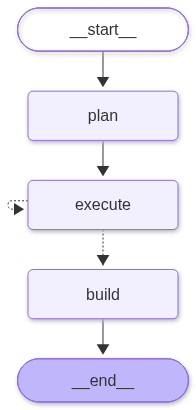

In [12]:
def build_node(state: AgentState) -> dict:
    """Hand the finished sections to the Word tool."""
    print("[build] creating the Word document...")
    file_name = create_word_document.invoke({
        "title": state["title"],
        "doc_type": state["doc_type"],
        "assumptions": state["assumptions"],
        "tasks": state["tasks"],
        "sections": state["sections"],
    })
    return {"doc_path": file_name}


def route_after_execute(state: AgentState) -> str:
    """The loop: keep executing until every task in the TODO list is done."""
    return "execute" if state["current"] < len(state["tasks"]) else "build"


builder = StateGraph(AgentState)
builder.add_node("plan", plan_node)
builder.add_node("execute", execute_node)
builder.add_node("build", build_node)

builder.add_edge(START, "plan")
builder.add_edge("plan", "execute")
builder.add_conditional_edges("execute", route_after_execute, {"execute": "execute", "build": "build"})
builder.add_edge("build", END)

graph = builder.compile()
show(graph)

## Part 7: run the whole agent

First the standard request. The `recursion_limit` is our safety net from Lab 2.

In [13]:
result = graph.invoke(
    {"request": STANDARD_REQUEST, "sections": [], "current": 0},
    config={"recursion_limit": 50},
)
print("\nDONE ->", result["title"], "|", len(result["sections"]), "sections |", result["doc_path"])

[plan] planning...
[execute] task 1/6: Objectives and MVP scope
[execute] task 2/6: Team, roles, and ways of working
[execute] task 3/6: Timeline and milestones
[execute] task 4/6: Workstreams and deliverables
[execute] task 5/6: Risks and mitigations
[execute] task 6/6: Launch readiness and success measurement
[build] creating the Word document...

DONE -> Three-Month Mobile App Launch Plan | 6 sections | a35457f6.docx


Now the complex request, streamed so you can watch each node finish. This is the one to demo: ambiguous, missing information and a conflict.

In [14]:
for step in graph.stream(
    {"request": COMPLEX_REQUEST, "sections": [], "current": 0},
    config={"recursion_limit": 50},
    stream_mode="updates",
):
    node = list(step.keys())[0]
    print("finished node:", node)
    if node == "plan":
        show_plan({**step["plan"]})

[plan] planning...
finished node: plan
TITLE: Detailed, Fast-Start Client Proposal | Client proposal
ASSUMPTIONS:
  - The client’s industry, organization, specific needs, and decision-makers are not yet known; the proposal will use adaptable language and clearly marked placeholders rather than assume facts.
  - No budget or pricing inputs were provided; the proposal will present a pricing structure with placeholders, not an invented price.
  - “Ready fast” means the proposal should be easy to finalize once client details are supplied. A relative, illustrative delivery timeline will be included and validated with the client.
  - To balance speed and detail, the proposal will be comprehensive but structured for quick review, with detailed scope, timeline, assumptions, and risks.
TASKS:
  1. Executive Summary and Client Objectives: Frame the proposal’s purpose, summarize the value offered, and identify client-specific objectives as placeholders for confirmation.
  2. Proposed Approach and

Open both `.docx` files in the `outputs` folder. Check the complex one: assumptions about the missing industry and budget, the fast-versus-detailed conflict resolved explicitly, a risks section, a timeline.

## Part 8: the API

`api.py` is the FastAPI front door: `POST /agent`, `GET /download/{name}`, `GET /health`, with Pydantic validation (10 to 2000 characters, no blank input) and error mapping (422 invalid input, 502 when the LLM fails after retries and fallback, 500 otherwise).

Here we test it from inside the notebook with `TestClient`. The first cells need no LLM calls.

In [ ]:
from fastapi.testclient import TestClient
from api import app

client = TestClient(app)

print("health        :", client.get("/health").json())
print("too short     :", client.post("/agent", json={"request": "hi"}).status_code, "(expect 422)")
print("blank         :", client.post("/agent", json={"request": "            "}).status_code, "(expect 422)")
print("bad extension :", client.get("/download/secret.txt").status_code, "(expect 404)")
print("traversal     :", client.get("/download/..%2F.env").status_code, "(expect 404)")

In [ ]:
r = client.post("/agent", json={"request": COMPLEX_REQUEST})
print(r.status_code)
body = r.json()
print(body["message"])
for a in body["assumptions"]:
    print("  assumption:", a)
for t in body["task_list"]:
    print(f"  {t['id']}. {t['section']}")
print("Download:", body["download_url"])

To run it as a real server, open a terminal in this folder and run:

```
uvicorn api:app --reload
```
then open `http://127.0.0.1:8000/docs`, click **POST /agent**, **Try it out**, and paste `{"request": "..."}`.

## Recap, and the video

You built an agent whose graph is `plan -> execute (loop) -> build`, with Pydantic structured output on every LLM call and retry plus fallback underneath.

For the four video segments (record on **video.fluid.ai** only, never a Drive link):

| Segment | What to say |
|---|---|
| Live demo (3-4 min) | Run both requests in `/docs`. Point at the task list, the assumptions, then open the two Word files. |
| What you built (2-3 min) | Draw the graph. FastAPI, LangGraph state with a reducer, the planner, the executor loop, the Word tool, `ask`. |
| Debugging (1-2 min) | One real bug you hit (for example a plan with no tasks, or a wrong model name from Lab 1 Test 2). Symptom, root cause, fix. |
| Tradeoff (1-2 min) | Autonomous planning versus a deterministic workflow: the LLM plan is flexible but less predictable, so we added Pydantic validation, a 7-task cap, a recursion limit and retry/fallback. Also: LangGraph by hand versus `create_agent`. |

**Mandatory improvement answer:** *Retry and fallback. LLM calls fail through rate limits, timeouts and replies that break the schema. `ask` validates every reply with Pydantic, retries the primary model twice, falls back to a second model, logs each failure, and raises one clear error, so a single bad response no longer crashes the request.*

### Exercise


Add a reflection node after the executor loop: it asks the model to review each section (your `Review` schema from Lab 1), and any section scoring below 7 is rewritten once. That is a second improvement, so only mention it as future work in the video unless you finish early. A stretch challenge: use `create_agent` for the executor with a `ModelCallLimitMiddleware`, and compare it with the hand-written loop.